# Úloha 3: vek, slabo používaná ruka a tras jednotlivých prstov

**Zadanie:** *Urobiť základnú štatistickú analýzu pre porovnanie ľudí podľa veku (hist po 10 rokov), medzi
zdravými a pacientmi, určiť počty pacientov, ktorí slabo používajú jednu ruku, navrhnúť analýzu trasu podľa
jednotlivých prstov (napr. či sa niektoré prsty trasú viac ako iné, či je rozdiel medzi trasom na jednotlivých
prstoch u jedného človeka a pod.)*

**Dáta:** hra EXACT_FORCE (držanie rovnomernej sily všetkými prstami, 4 iterácie po 16 s, analyzuje sa úsek 3–15 s),
138 ľudí: 90 zdravých (78 TUKE 2025-02, 12 starších 9_9_2026) a 48 pacientov (83 vyšetrení).

**Postup** nadväzuje na `features_tremor.ipynb` (úloha 2) a používa rovnaké spracovanie:
- tras = zložka sily 3,5–15 Hz, meraná **len v ustálených úsekoch** (bez prudkých stlačení a uvoľnení, ktoré
  by tras umelo zvýšili),
- tras sa **upravuje na silu prsta** (silnejšie tlačiaci prst sa trasie viac aj u zdravých),
- prst, ktorý netlačí (sila ≤ 0,003), sa do trasu nezapočíta.

Kód: `rehapiano_features.py` (spracovanie z úlohy 2) a `rehapiano_fingers.py` (táto úloha).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import mannwhitneyu

import rehapiano_features as rf
import rehapiano_fingers as fg

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
GROUPS = ["zdraví TUKE 2025-02", "zdraví 9_9_2026 (starší)", "pacienti"]
COLORS = {"zdraví TUKE 2025-02": "#2a78d6", "zdraví 9_9_2026 (starší)": "#1baf7a", "pacienti": "#eb6834"}
C_HEALTHY, C_PATIENT = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
    "figure.dpi": 110,
})
FIG_DIR = __import__("pathlib").Path("figures"); FIG_DIR.mkdir(exist_ok=True)
pct = lambda a, b: f"{a} z {b} ({100 * a / b:.0f} %)"

exams, _ = rf.build_exam_table()
X, _ = rf.load_all(exams)                       # (vyšetrenia, 4 iterácie, 1200 vzoriek, 10 prstov), 100 Hz
FING, _ = rf.compute_finger_features(X, exams)  # prst × iterácia, tras upravený na silu (úloha 2, krok 5)
PEOPLE = fg.person_table(exams)
N_PAT = int((PEOPLE.skupina == "pacient").sum()); N_HEALTHY = int((PEOPLE.skupina == "zdravý").sum())
print(f"vyšetrení: {len(exams)}, ľudí: {len(PEOPLE)} ({N_HEALTHY} zdravých, {N_PAT} pacientov), "
      f"riadkov prst × iterácia: {len(FING)}")

vyšetrení: 173, ľudí: 138 (90 zdravých, 48 pacientov), riadkov prst × iterácia: 6284


## 1. Vek: zdraví vs. pacienti

Každý človek sa počíta **raz** (vek pri prvom vyšetrení). Zdraví sú rozdelení na dve podskupiny, lebo sú to
dve rozdielne merania: študenti TUKE (február 2025) a starší ľudia (9. 9. 2026).

In [2]:
summary = PEOPLE.groupby("podskupina").agg(
    ludi=("patient_id", "size"), vek_median=("vek", "median"),
    vek_Q1=("vek", lambda v: v.quantile(0.25)), vek_Q3=("vek", lambda v: v.quantile(0.75)),
    vek_min=("vek", "min"), vek_max=("vek", "max"),
    zeny=("pohlavie", lambda s: int((s == "female").sum())), muzi=("pohlavie", lambda s: int((s == "male").sum())),
    vek_50_a_viac=("vek", lambda v: int((v >= 50).sum()))).loc[GROUPS]
display(summary)
counts = pd.crosstab(PEOPLE.vekova_skupina, PEOPLE.podskupina).reindex(columns=GROUPS)
counts["zdraví spolu"] = counts[GROUPS[0]] + counts[GROUPS[1]]
display(counts)

H, PAT = PEOPLE.skupina == "zdravý", PEOPLE.skupina == "pacient"
for name, ref in [("všetci zdraví", H), ("zdraví ≥ 50 rokov", H & (PEOPLE.vek >= 50)),
                  ("zdraví 9_9_2026", PEOPLE.podskupina == GROUPS[1])]:
    p = mannwhitneyu(PEOPLE.vek[PAT], PEOPLE.vek[ref]).pvalue
    print(f"Vek pacientov vs. {name} (n={ref.sum()}): medián {PEOPLE.vek[PAT].median():.1f} vs. "
          f"{PEOPLE.vek[ref].median():.1f} rokov, Mann-Whitneyho test p = {p:.2g}")

,ludi,vek_median,vek_Q1,vek_Q3,vek_min,vek_max,zeny,muzi,vek_50_a_viac
podskupina,,,,,,,,,
zdraví TUKE 2025-02,78,23.0,21.0,34.00,18,79,24,54,12
zdraví 9_9_2026 (starší),12,69.0,65.0,75.00,56,85,12,0,12
pacienti,48,66.5,56.0,74.25,21,89,20,28,40


podskupina,zdraví TUKE 2025-02,zdraví 9_9_2026 (starší),pacienti,zdraví spolu
vekova_skupina,,,,
10–19,8,0,0,8
20–29,48,0,4,48
30–39,6,0,2,6
40–49,4,0,2,4
50–59,5,1,8,6
60–69,6,5,13,11
70–79,1,4,14,5
80–89,0,2,5,2


Vek pacientov vs. všetci zdraví (n=90): medián 66.5 vs. 24.0 rokov, Mann-Whitneyho test p = 1.8e-10
Vek pacientov vs. zdraví ≥ 50 rokov (n=24): medián 66.5 vs. 64.5 rokov, Mann-Whitneyho test p = 0.98
Vek pacientov vs. zdraví 9_9_2026 (n=12): medián 66.5 vs. 69.0 rokov, Mann-Whitneyho test p = 0.21


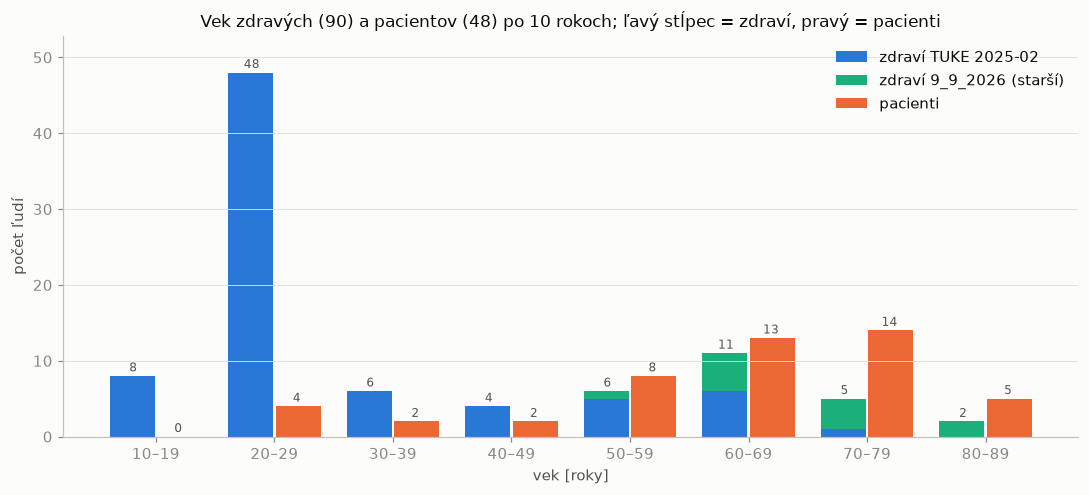

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(counts)); w = 0.38
bottom = np.zeros(len(counts))
for g in GROUPS[:2]:
    ax.bar(x - w / 2 - 0.01, counts[g], w, bottom=bottom, color=COLORS[g], label=g)
    bottom += counts[g].to_numpy()
ax.bar(x + w / 2 + 0.01, counts["pacienti"], w, color=COLORS["pacienti"], label="pacienti")
for i in range(len(counts)):
    ax.text(x[i] - w / 2, bottom[i] + 0.6, int(bottom[i]), ha="center", fontsize=8, color=INK2)
    ax.text(x[i] + w / 2, counts["pacienti"].iat[i] + 0.6, int(counts["pacienti"].iat[i]), ha="center", fontsize=8,
            color=INK2)
ax.set_xticks(x, counts.index.astype(str)); ax.grid(axis="x", visible=False)
ax.set_ylim(0, bottom.max() * 1.1)
ax.set_xlabel("vek [roky]"); ax.set_ylabel("počet ľudí")
ax.set_title(f"Vek zdravých ({N_HEALTHY}) a pacientov ({N_PAT}) po 10 rokoch; ľavý stĺpec = zdraví, pravý = pacienti")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "18_histogram_veku.png", dpi=150); plt.show()

**Záver 1:**
- Skupiny majú **veľmi rozdielny vek**: zdraví sú prevažne mladí študenti (medián 24 rokov, 48 z 90 má 20–29
  rokov), pacienti sú prevažne starší (medián 66,5 roka, 27 zo 48 má 60–79 rokov).
- **Porovnateľných vekom** je len 24 zdravých ≥ 50 rokov (12 z 9_9_2026 a 12 z TUKE) oproti 40 pacientom ≥ 50;
  vekom sa od pacientov nelíšia (medián 64,5 vs. 66,5 roka, p = 0,98). Medzi pacientmi je viac mužov (28 zo 48).
- Preto sa výsledky trasu nižšie overujú aj voči zdravým ≥ 50 rokov. V úlohe 2 sme overili, že tras
  v ustálených úsekoch sa medzi mladými a staršími zdravými nelíši (mediány 0,098 vs. 0,087 vs. 0,096 × 10⁻³),
  takže ako hlavnú normu možno použiť všetkých 90 zdravých.

## 2. Koľko pacientov slabo používa jednu ruku

**Ako to meriame** (rovnaké pravidlo ako v úlohe 2, krok 4). Pre každé vyšetrenie:
- **sila ruky** = súčet priemerných síl jej 5 prstov,
- **pomer rúk** = slabšia ruka / silnejšia ruka (1 = obe rovnako, 0 = jedna netlačí).

Ruka je **málo používaná**, ak je slabá **naraz v oboch**: sila slabšej ruky aj pomer rúk sú nižšie ako
u 97,5 % zdravých (2,5. percentil). Samotný pomer nestačí – aj zdravý človek môže tlačiť jednou rukou
o polovicu menej, ak druhou tlačí veľmi silno. **Nepoužívaná** ruka = súčet síl < 0,01 (takmer netlačí).

Pacienti majú väčšinou 2 vyšetrenia, preto počítame na úrovni človeka tri varianty:
- **aspoň v jednom vyšetrení** – ruka bola slabá aspoň raz,
- **vo väčšine vyšetrení** – ruka bola slabá vo viac ako polovici vyšetrení (pri 1 vyšetrení = v ňom),
- **z priemeru vyšetrení** – najprv priemer síl cez vyšetrenia, potom prah (takto to počíta kolega).

In [4]:
HANDS, LEVEL_THR, RATIO_THR = fg.hand_table(X, exams)
print(f"Prahy zo zdravých (2,5. percentil): sila slabšej ruky < {LEVEL_THR:.3f}, pomer rúk < {RATIO_THR:.2f}")
print("Vyšetrenia podľa stavu slabšej ruky:")
display(pd.crosstab(HANDS.podskupina, HANDS.stav).reindex(GROUPS))

WEAK = fg.weak_hand_people(HANDS, LEVEL_THR, RATIO_THR)
tab = WEAK.groupby("skupina")[["aspon_raz", "vo_vacsine", "z_priemeru"]].sum().astype(int)
tab["ludi"] = WEAK.groupby("skupina").size()
tab = tab.rename(columns={"aspon_raz": "aspoň v 1 vyšetrení", "vo_vacsine": "vo väčšine vyšetrení",
                          "z_priemeru": "z priemeru vyšetrení"}).loc[["pacient", "zdravý"]]
print("Počet ľudí s málo používanou rukou:")
display(tab)
flagged = WEAK[WEAK.aspon_raz | WEAK.z_priemeru].sort_values(["skupina", "pomer_min"])
display(flagged[["patient_id", "skupina", "vek", "vysetreni", "slabych_vysetreni", "slabsia_ruka", "pomer_min",
                 "pomer_max", "pomer_z_priemeru", "aspon_raz", "vo_vacsine", "z_priemeru"]]
        .set_index("patient_id").round(2))

Prahy zo zdravých (2,5. percentil): sila slabšej ruky < 0.068, pomer rúk < 0.56
Vyšetrenia podľa stavu slabšej ruky:


stav,málo používaná,v norme
podskupina,,
zdraví TUKE 2025-02,3,75
zdraví 9_9_2026 (starší),0,12
pacienti,12,71


Počet ľudí s málo používanou rukou:


,aspoň v 1 vyšetrení,vo väčšine vyšetrení,z priemeru vyšetrení,ludi
skupina,,,,
pacient,9,5,6,48
zdravý,3,3,3,90


,skupina,vek,vysetreni,slabych_vysetreni,slabsia_ruka,pomer_min,pomer_max,pomer_z_priemeru,aspon_raz,vo_vacsine,z_priemeru
patient_id,,,,,,,,,,,
EJIT-XSEZ,pacient,76,2,2,pravá,0.16,0.50,0.34,True,True,True
0IKB-27Y1,pacient,75,1,1,ľavá,0.19,0.19,0.19,True,True,True
3OUS-NI9J,pacient,82,2,2,ľavá,0.27,0.29,0.28,True,True,True
XT2X-WLNW,pacient,67,2,1,pravá,0.40,0.70,0.55,True,False,True
ILHC-BZCP,pacient,73,2,2,pravá,0.42,0.43,0.43,True,True,True
6JRZ-KPE6,pacient,51,2,1,ľavá,0.42,0.96,0.74,True,False,False
OQHZ-N4AV,pacient,60,2,1,pravá,0.43,0.93,0.65,True,False,False
W6JM-R0SG,pacient,58,1,1,pravá,0.47,0.47,0.47,True,True,True
NUYV-81KG,pacient,88,2,1,ľavá,0.50,0.63,0.57,True,False,False


**Citlivosť na prah:** ako sa počty zmenia, ak prahy nastavíme na 1. alebo 5. percentil zdravých.

In [5]:
rows = []
for p in [1, 2.5, 5]:
    h, lt, rt = fg.hand_table(X, exams, pct=p)
    wp = fg.weak_hand_people(h, lt, rt)
    for grp, n in [("pacient", N_PAT), ("zdravý", N_HEALTHY)]:
        s = wp[wp.skupina == grp]
        rows.append({"percentil zdravých": p, "prah sily": round(lt, 3), "prah pomeru": round(rt, 2), "skupina": grp,
                     "aspoň v 1 vyšetrení": int(s.aspon_raz.sum()), "vo väčšine": int(s.vo_vacsine.sum()),
                     "z priemeru": int(s.z_priemeru.sum()), "ľudí": n})
display(pd.DataFrame(rows).set_index(["percentil zdravých", "skupina"]))

prah sily  prah pomeru  aspoň v 1 vyšetrení  \
percentil zdravých skupina                                                
1.0                pacient      0.050         0.45                    6   
                   zdravý       0.050         0.45                    1   
2.5                pacient      0.068         0.56                    9   
                   zdravý       0.068         0.56                    3   
5.0                pacient      0.075         0.68                   11   
                   zdravý       0.075         0.68                    5   

                            vo väčšine  z priemeru  ľudí  
percentil zdravých skupina                                
1.0                pacient           3           4    48  
                   zdravý            1           1    90  
2.5                pacient           5           6    48  
                   zdravý            3           3    90  
5.0                pacient           6           8    48  
                   zdravý            5           5    90

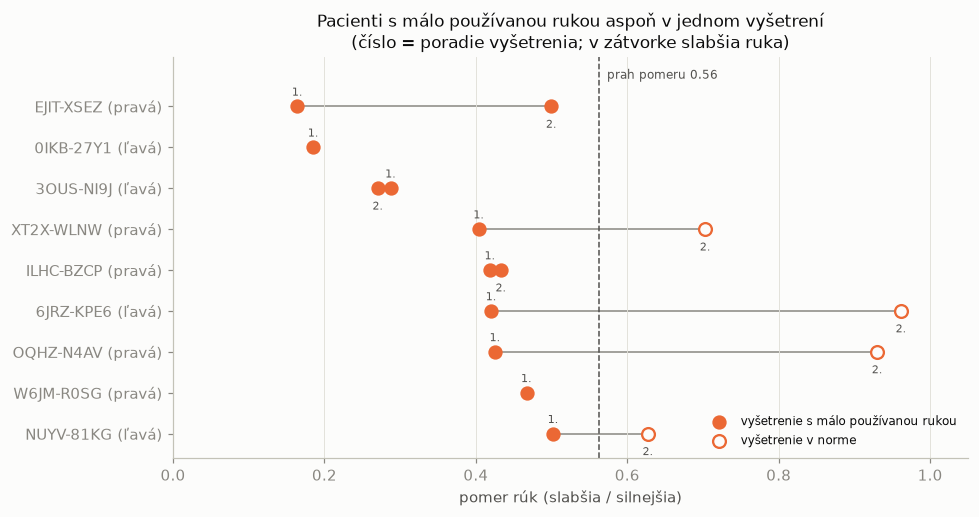

In [6]:
pw = flagged[flagged.skupina == "pacient"].sort_values("pomer_min", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
for y, pid in enumerate(pw.patient_id):
    e = HANDS[HANDS.patient_id == pid].sort_values("datum")
    ax.plot(e.pomer_ruk, [y] * len(e), color=MUTED, lw=1, zorder=1)
    weak = (e.stav != "v norme").to_numpy()
    ax.scatter(e.pomer_ruk[weak], [y] * weak.sum(), s=70, color=C_PATIENT, zorder=2,
               label="vyšetrenie s málo používanou rukou" if y == 0 else None)
    ax.scatter(e.pomer_ruk[~weak], [y] * (~weak).sum(), s=70, facecolors=SURFACE, edgecolors=C_PATIENT, lw=1.5,
               zorder=2, label="vyšetrenie v norme" if y == 0 else None)
    for k, (_, r) in enumerate(e.iterrows()):
        ax.annotate(f"{k + 1}.", (r.pomer_ruk, y), xytext=(0, 7 if k % 2 == 0 else -14), textcoords="offset points", ha="center",
                    fontsize=7, color=INK2)
ax.axvline(RATIO_THR, color=INK2, ls="--", lw=1)
ax.text(RATIO_THR, len(pw) - 0.4, f"  prah pomeru {RATIO_THR:.2f}", fontsize=8, color=INK2, va="bottom")
ax.set_yticks(range(len(pw)), [f"{r.patient_id} ({r.slabsia_ruka})" for _, r in pw.iterrows()])
ax.set_xlim(0, 1.05); ax.set_ylim(-0.6, len(pw) + 0.2); ax.grid(axis="y", visible=False)
ax.set_xlabel("pomer rúk (slabšia / silnejšia)")
ax.set_title("Pacienti s málo používanou rukou aspoň v jednom vyšetrení\n(číslo = poradie vyšetrenia; v zátvorke slabšia ruka)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "19_slaba_ruka.png", dpi=150); plt.show()

In [7]:
p_tab = tab.loc["pacient"]; h_tab = tab.loc["zdravý"]
display(Markdown(f'''
**Záver 2:**
- **Úplne nepoužívanú ruku nemá nikto** (ani pacient, ani zdravý).
- **Málo používanú ruku** má:
  - **aspoň v jednom vyšetrení {pct(p_tab.iloc[0], N_PAT)} pacientov**,
  - **vo väčšine vyšetrení {pct(p_tab.iloc[1], N_PAT)}** (tí majú slabú ruku stabilne),
  - z priemeru vyšetrení {pct(p_tab.iloc[2], N_PAT)} (výsledok kolegu).
- U zdravých je to {pct(h_tab.iloc[0], N_HEALTHY)} – to zodpovedá voľbe prahu (2,5 % zdravých z definície).
- Rozdiel 9 vs. 6 je len v tom, či sa vyšetrenia najprv spriemerujú: OQHZ-N4AV, 6JRZ-KPE6 a NUYV-81KG
  mali slabú ruku v jednom vyšetrení a v druhom nie. U OQHZ-N4AV a 6JRZ-KPE6 je slabá ruka v **prvom**
  vyšetrení a o ~10 dní neskôr je pomer rúk v norme – môže to byť zlepšenie počas rehabilitácie
  (alebo len kolísanie; z dvoch meraní sa to rozhodnúť nedá).
- Slabšia ruka: pravá u {(pw.slabsia_ruka == 'pravá').sum()}, ľavá u {(pw.slabsia_ruka == 'ľavá').sum()} pacientov – ani jedna strana neprevažuje.
'''))


**Záver 2:**
- **Úplne nepoužívanú ruku nemá nikto** (ani pacient, ani zdravý).
- **Málo používanú ruku** má:
  - **aspoň v jednom vyšetrení 9 z 48 (19 %) pacientov**,
  - **vo väčšine vyšetrení 5 z 48 (10 %)** (tí majú slabú ruku stabilne),
  - z priemeru vyšetrení 6 z 48 (12 %) (výsledok kolegu).
- U zdravých je to 3 z 90 (3 %) – to zodpovedá voľbe prahu (2,5 % zdravých z definície).
- Rozdiel 9 vs. 6 je len v tom, či sa vyšetrenia najprv spriemerujú: OQHZ-N4AV, 6JRZ-KPE6 a NUYV-81KG
  mali slabú ruku v jednom vyšetrení a v druhom nie. U OQHZ-N4AV a 6JRZ-KPE6 je slabá ruka v **prvom**
  vyšetrení a o ~10 dní neskôr je pomer rúk v norme – môže to byť zlepšenie počas rehabilitácie
  (alebo len kolísanie; z dvoch meraní sa to rozhodnúť nedá).
- Slabšia ruka: pravá u 5, ľavá u 4 pacientov – ani jedna strana neprevažuje.


## 3. Tras jednotlivých prstov

### Ako tras prsta meriame

Každý prst počas držania sily trochu „dŕža“. Čím silnejšie prst tlačí, tým viac dŕža – **aj u zdravého**
človeka (palec tlačí ~9× silnejšie ako malíček). Priame porovnanie prstov by preto ukázalo hlavne to, ktorý
prst tlačí silnejšie.

Preto každý prst porovnávame s **normou**: koľko dŕža prst zdravého človeka, ktorý tlačí **rovnakou silou**
(`tras_relativny` z úlohy 2). **1 = ako zdraví, 3 = trikrát viac ako zdraví.**
Pre každého človeka a prst berieme medián cez všetky jeho iterácie (aj z viacerých vyšetrení).

Odpovedáme na tri otázky:
1. Je tras na každom prste vôbec merateľný (nad šumom snímača)?
2. Ktoré prsty sa trasú viac – prirodzene u zdravých a navyše u pacientov?
3. Trasú sa u jedného človeka všetky prsty rovnako, alebo len niektoré?

**Poradie prstov:** kanály 0 a 8 tlačia v oboch rukách najslabšie a kanály 4 a 12 najsilnejšie, preto ich
označujeme ako malíček … palec. Toto priradenie je **odvodené zo síl, nie overené** v dokumentácii zariadenia.

In [8]:
PF = fg.person_finger_table(FING, exams)
PF["nazov"] = PF.prst.map(fg.FINGER_LABEL)
LABELS = [fg.FINGER_LABEL[c] for c in rf.FINGER_NAMES]
force = PF.pivot_table(index="nazov", columns="skupina", values="sila", aggfunc="median").reindex(LABELS)
active = PF.groupby(["nazov", "skupina"]).size().unstack().reindex(LABELS)
print("Medián sily prsta [a.u.] a počet ľudí, u ktorých prst tlačí (sila > 0,003):")
display(pd.concat({"sila (medián)": force.round(4), "aktívny u ľudí": active}, axis=1))

Medián sily prsta [a.u.] a počet ľudí, u ktorých prst tlačí (sila > 0,003):


sila (medián)         aktívny u ľudí       
skupina              pacient  zdravý        pacient zdravý
nazov                                                     
ľ. malíček            0.0074  0.0064             43     78
ľ. prstenník          0.0101  0.0105             48     90
ľ. prostredník        0.0135  0.0121             48     84
ľ. ukazovák           0.0188  0.0211             48     89
ľ. palec              0.0456  0.0495             48     89
p. malíček            0.0078  0.0066             43     72
p. prstenník          0.0103  0.0096             48     80
p. prostredník        0.0110  0.0115             48     82
p. ukazovák           0.0203  0.0237             48     89
p. palec              0.0462  0.0492             48     90

### 3.1 Je tras merateľný? Porovnanie so šumom snímača

V kalibračných meraniach (`25_03_2025_calibration`) sú iterácie a kanály, na ktoré nikto netlačí. Ich „tras“
(rovnaké spracovanie ako v hre) je čistý **šum snímača**. Ak je tras prsta len o málo väčší ako šum, meranie
na tomto prste je nespoľahlivé a rozdiely na ňom sú zmenšené šumom.

In [9]:
CAL = fg.calibration_noise()
un = CAL[CAL.nezatazeny]
NOISE = float(un.tras_SD.median())
print(f"Kalibrácia: {len(CAL)} kanál × iterácia, nezaťažených {len(un)}; "
      f"šum (SD trasu nezaťaženého snímača): medián {NOISE * 1e3:.4f} × 10⁻³, "
      f"95. percentil {un.tras_SD.quantile(0.95) * 1e3:.4f} × 10⁻³")
display((un.groupby("prst").tras_SD.median().reindex(rf.FINGER_NAMES).rename(index=fg.FINGER_LABEL) * 1e3)
        .round(4).to_frame("šum podľa kanála [×10⁻³]").T)
snr = (PF.pivot_table(index="nazov", columns="skupina", values="tras_SD", aggfunc="median").reindex(LABELS) / NOISE)
below = PF.assign(pod=PF.tras_SD < 2 * NOISE).pivot_table(index="nazov", columns="skupina", values="pod",
                                                          aggfunc="mean").reindex(LABELS) * 100
print("Koľkokrát je tras prsta (medián) väčší ako šum, a podiel ľudí s trasom pod 2× šumom [%]:")
display(pd.concat({"tras / šum": snr.round(1), "% ľudí pod 2× šumom": below.round(0)}, axis=1))

Kalibrácia: 260 kanál × iterácia, nezaťažených 194; šum (SD trasu nezaťaženého snímača): medián 0.0284 × 10⁻³, 95. percentil 0.0853 × 10⁻³


prst,ľ. malíček,ľ. prstenník,ľ. prostredník,ľ. ukazovák,ľ. palec,p. malíček,p. prstenník,p. prostredník,p. ukazovák,p. palec
šum podľa kanála [×10⁻³],0.0281,0.0278,0.027,0.0287,0.028,0.0293,0.0283,0.0266,0.0278,0.0307


Koľkokrát je tras prsta (medián) väčší ako šum, a podiel ľudí s trasom pod 2× šumom [%]:


tras / šum        % ľudí pod 2× šumom       
skupina           pacient zdravý             pacient zdravý
nazov                                                      
ľ. malíček            7.6    4.4                 2.0   12.0
ľ. prstenník          2.2    1.9                48.0   57.0
ľ. prostredník        3.3    2.0                17.0   46.0
ľ. ukazovák           5.3    3.1                 6.0   22.0
ľ. palec             11.9    5.9                 2.0    2.0
p. malíček            9.5    6.0                 2.0    7.0
p. prstenník          2.5    1.8                29.0   62.0
p. prostredník        3.2    2.1                19.0   50.0
p. ukazovák           5.2    3.4                 4.0   13.0
p. palec             11.2    6.1                 0.0    2.0

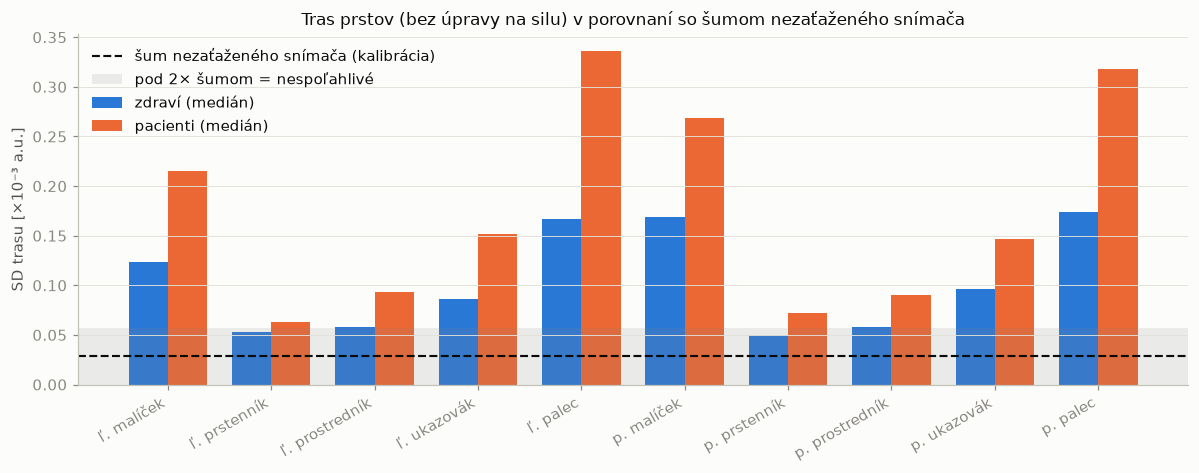

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(LABELS)); w = 0.38
med = PF.pivot_table(index="nazov", columns="skupina", values="tras_SD", aggfunc="median").reindex(LABELS) * 1e3
ax.bar(x - w / 2, med["zdravý"], w, color=C_HEALTHY, label="zdraví (medián)")
ax.bar(x + w / 2, med["pacient"], w, color=C_PATIENT, label="pacienti (medián)")
ax.axhline(NOISE * 1e3, color=INK, lw=1.4, ls="--", label="šum nezaťaženého snímača (kalibrácia)")
ax.axhspan(0, 2 * NOISE * 1e3, color=MUTED, alpha=0.15, lw=0, label="pod 2× šumom = nespoľahlivé")
ax.set_xticks(x, LABELS, rotation=30, ha="right"); ax.grid(axis="x", visible=False)
ax.set_ylabel("SD trasu [×10⁻³ a.u.]")
ax.set_title("Tras prstov (bez úpravy na silu) v porovnaní so šumom nezaťaženého snímača")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "20_tras_vs_sum.png", dpi=150); plt.show()

**Záver 3.1:** tras je nad šumom na všetkých prstoch, ale nie rovnako spoľahlivo:
- **prstenníky a prostredníky** zdravých majú tras len ~2× väčší ako šum snímača (u polovice zdravých je pod
  2× šumom) – tu je meranie najmenej spoľahlivé a skutočné rozdiely medzi ľuďmi sa šumom „rozmažú“
  (vyzerajú menšie),
- **ukazováky** sú ~3× nad šumom, **malíčky a palce** 4–6× (u pacientov ešte viac).

### 3.2 Ktoré prsty sa trasú viac?

**a) Prirodzené rozdiely u zdravých.** Ak by úprava na silu vysvetlila všetko, každý prst zdravého by mal ~1.
Friedmanov test porovnáva prsty **u toho istého človeka** (zdraví so všetkými 10 aktívnymi prstami);
Kendallovo W hovorí, aké silné sú rozdiely (0 = žiadne, 1 = u všetkých ľudí rovnaké poradie prstov).

Friedmanov test (zdraví, n = 49): chi² = 186, p = 2e-35, Kendallovo W = 0.42


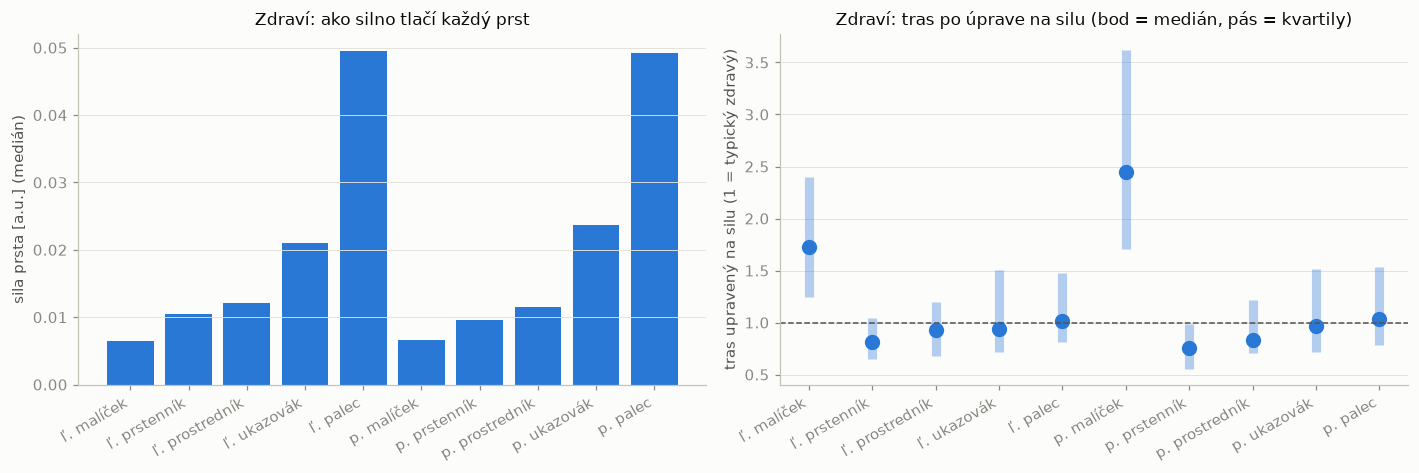

In [11]:
FT = fg.healthy_finger_test(PF)
print(f"Friedmanov test (zdraví, n = {FT['ludi']}): chi² = {FT['chi2']:.0f}, p = {FT['p']:.1g}, "
      f"Kendallovo W = {FT['kendall_W']:.2f}")
hq = PF[PF.skupina == "zdravý"].groupby("nazov").tras_relativny.quantile([0.25, 0.5, 0.75]).unstack().reindex(LABELS)
hf = PF[PF.skupina == "zdravý"].groupby("nazov").sila.median().reindex(LABELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].bar(x, hf, color=C_HEALTHY)
axes[0].set_ylabel("sila prsta [a.u.] (medián)"); axes[0].set_title("Zdraví: ako silno tlačí každý prst")
axes[1].vlines(x, hq[0.25], hq[0.75], color=C_HEALTHY, lw=6, alpha=0.35)
axes[1].plot(x, hq[0.5], "o", ms=9, color=C_HEALTHY)
axes[1].axhline(1, color=INK2, ls="--", lw=1)
axes[1].set_ylabel("tras upravený na silu (1 = typický zdravý)")
axes[1].set_title("Zdraví: tras po úprave na silu (bod = medián, pás = kvartily)")
for ax in axes:
    ax.set_xticks(x, LABELS, rotation=30, ha="right"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "21_prsty_zdravi.png", dpi=150); plt.show()

**Záver 3.2a:** áno, **prsty sa líšia už u zdravých** a rozdiely sú veľké a u ľudí rovnaké (Kendallovo W ≈ 0,4).
**Malíčky** sa trasú ~2× viac, než by zodpovedalo ich sile (tlačia najslabšie, ich kolísanie je relatívne veľké),
**prstenníky** naopak menej (~0,8). Pre porovnanie s pacientmi preto nestačí jedna spoločná norma –
každý prst pacienta treba porovnať s **tým istým prstom** zdravých. To robíme ďalej.

**b) Pacienti vs. zdraví pre každý prst.** Pomer = medián pacientov / medián zdravých pre ten istý prst
(1 = rovnako, 2 = pacienti dvakrát viac). 95 % interval spoľahlivosti je z bootstrapu (2000×, výber ľudí),
p-hodnoty z Mann-Whitneyho testu s Holmovou korekciou na 10 prstov. Kontrola veku: rovnaký výpočet len so
zdravými ≥ 50 rokov.

,n_pacienti,n_zdravi,median_pacienti,median_zdravi,pomer,CI_lo,CI_hi,p_holm,pomer vs. zdraví ≥ 50,p_holm vs. ≥ 50
nazov,,,,,,,,,,
ľ. malíček,43,78,2.84,1.73,1.64,1.13,2.15,0.00094,1.47,0.09
ľ. prstenník,48,90,0.89,0.81,1.10,0.90,1.51,0.18,1.20,0.34
ľ. prostredník,48,84,1.31,0.93,1.41,1.26,1.81,2.6e-05,1.60,0.012
ľ. ukazovák,48,89,1.70,0.94,1.81,1.39,2.16,7.9e-05,1.69,0.09
ľ. palec,48,89,2.08,1.02,2.05,1.53,2.60,4.1e-06,2.07,0.0022
p. malíček,43,72,4.00,2.45,1.63,1.26,2.05,0.00023,1.82,0.0034
p. prstenník,48,80,1.07,0.76,1.42,1.25,1.68,0.00094,1.32,0.16
p. prostredník,48,82,1.27,0.83,1.54,1.31,2.04,0.00011,1.49,0.09
p. ukazovák,48,89,1.83,0.96,1.89,1.41,2.38,4.1e-06,2.06,0.0033


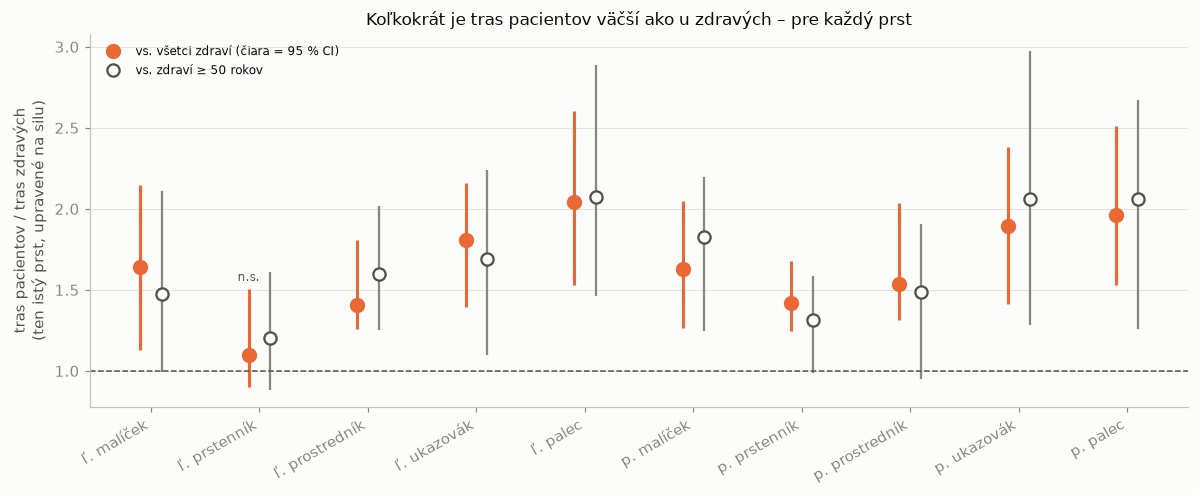

In [12]:
RATIO_ALL = fg.finger_group_ratio(PF)
RATIO_50 = fg.finger_group_ratio(PF, ref_mask=(PF.skupina == "zdravý") & (PF.vek >= 50))
show = RATIO_ALL[["nazov", "n_pacienti", "n_zdravi", "median_pacienti", "median_zdravi", "pomer", "CI_lo", "CI_hi",
                  "p_holm"]].copy()
show["pomer vs. zdraví ≥ 50"] = RATIO_50.pomer
show["p_holm vs. ≥ 50"] = RATIO_50.p_holm
display(show.set_index("nazov").style.format({"median_pacienti": "{:.2f}", "median_zdravi": "{:.2f}", "pomer": "{:.2f}",
                                               "CI_lo": "{:.2f}", "CI_hi": "{:.2f}", "pomer vs. zdraví ≥ 50": "{:.2f}",
                                               "p_holm": "{:.2g}", "p_holm vs. ≥ 50": "{:.2g}"}))

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.vlines(x - 0.1, RATIO_ALL.CI_lo, RATIO_ALL.CI_hi, color=C_PATIENT, lw=2)
ax.plot(x - 0.1, RATIO_ALL.pomer, "o", ms=9, color=C_PATIENT, label="vs. všetci zdraví (čiara = 95 % CI)")
ax.vlines(x + 0.1, RATIO_50.CI_lo, RATIO_50.CI_hi, color=MUTED, lw=1.5)
ax.plot(x + 0.1, RATIO_50.pomer, "o", ms=8, mfc=SURFACE, mec=INK2, mew=1.5, label="vs. zdraví ≥ 50 rokov")
ax.axhline(1, color=INK2, ls="--", lw=1)
for i, (s, n) in enumerate(zip(RATIO_ALL.p_holm, RATIO_ALL.nazov)):
    if s >= 0.05:
        ax.text(x[i] - 0.1, RATIO_ALL.CI_hi[i] + 0.05, "n.s.", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, LABELS, rotation=30, ha="right"); ax.grid(axis="x", visible=False)
ax.set_ylabel("tras pacientov / tras zdravých\n(ten istý prst, upravené na silu)")
ax.set_title("Koľkokrát je tras pacientov väčší ako u zdravých – pre každý prst")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "22_pacienti_vs_zdravi_prsty.png", dpi=150); plt.show()

In [13]:
# Ktorý prst je u pacienta najviac nad normou toho istého prsta (podiel voči mediánu zdravých pre prst)
W_REL = fg.wide(PF)
H_MED = W_REL.loc[PEOPLE.patient_id[H]].median()
NORM = W_REL / H_MED                                           # 1 = ako typický zdravý pre tento prst
pat_ids = PEOPLE.patient_id[PAT].to_numpy()
worst = NORM.loc[pat_ids].idxmax(axis=1).map(fg.FINGER_LABEL).value_counts().reindex(LABELS, fill_value=0)
print("U koľkých pacientov je daný prst najviac nad normou (zo všetkých jeho prstov):")
display(worst.to_frame("pacientov").T)
by_type = pd.Series({t: worst[[l for l in LABELS if l.endswith(t)]].sum() for t in fg.FINGER_ORDER})
print("Spolu za obe ruky:", ", ".join(f"{k} {v}" for k, v in by_type.items()))

U koľkých pacientov je daný prst najviac nad normou (zo všetkých jeho prstov):


,ľ. malíček,ľ. prstenník,ľ. prostredník,ľ. ukazovák,ľ. palec,p. malíček,p. prstenník,p. prostredník,p. ukazovák,p. palec
pacientov,9,1,0,11,6,3,1,3,6,8


Spolu za obe ruky: malíček 12, prstenník 2, prostredník 3, ukazovák 17, palec 14


In [14]:
top = RATIO_ALL.sort_values("pomer", ascending=False)
ns = RATIO_ALL[RATIO_ALL.p_holm >= 0.05].nazov.tolist()
display(Markdown(f'''
**Záver 3.2b:**
- Pacienti majú väčší tras **na všetkých prstoch** (pomer {RATIO_ALL.pomer.min():.1f}–{RATIO_ALL.pomer.max():.1f}×),
  voči všetkým zdravým. Voči zdravým ≥ 50 rokov sú pomery podobné ({RATIO_50.pomer.min():.1f}–{RATIO_50.pomer.max():.1f}×),
  ale pri len 24 zdravých je významných menej prstov ({int((RATIO_50.p_holm < 0.05).sum())} z 10).
- **Najviac sa líšia palce a ukazováky** ({", ".join(f"{r.nazov} {r.pomer:.1f}×" for _, r in top.head(4).iterrows())}),
  **najmenej prstenníky** ({", ".join(f"{r.nazov} {r.pomer:.1f}×" for _, r in RATIO_ALL[RATIO_ALL.nazov.str.contains("prstenník")].iterrows())}).
  {("Nevýznamný rozdiel (po Holmovej korekcii): " + ", ".join(ns) + ".") if ns else ""}
- Pozor pri interpretácii prstenníkov: ich tras je len ~2× nad šumom (3.1), takže menší rozdiel môže byť
  čiastočne spôsobený šumom, nie tým, že sa prstenníky u pacientov netrasú.
- Prst, ktorý je u pacienta najviac nad normou (súčet za obe ruky): {", ".join(f"{k} {v}×" for k, v in by_type.sort_values(ascending=False).items())}
  – najčastejšie ukazovák, palec alebo malíček, zriedka prstenník či prostredník.
- Ľavá a pravá ruka sa v priemere správajú rovnako.
'''))


**Záver 3.2b:**
- Pacienti majú väčší tras **na všetkých prstoch** (pomer 1.1–2.0×),
  voči všetkým zdravým. Voči zdravým ≥ 50 rokov sú pomery podobné (1.2–2.1×),
  ale pri len 24 zdravých je významných menej prstov (5 z 10).
- **Najviac sa líšia palce a ukazováky** (ľ. palec 2.0×, p. palec 2.0×, p. ukazovák 1.9×, ľ. ukazovák 1.8×),
  **najmenej prstenníky** (ľ. prstenník 1.1×, p. prstenník 1.4×).
  Nevýznamný rozdiel (po Holmovej korekcii): ľ. prstenník.
- Pozor pri interpretácii prstenníkov: ich tras je len ~2× nad šumom (3.1), takže menší rozdiel môže byť
  čiastočne spôsobený šumom, nie tým, že sa prstenníky u pacientov netrasú.
- Prst, ktorý je u pacienta najviac nad normou (súčet za obe ruky): ukazovák 17×, palec 14×, malíček 12×, prostredník 3×, prstenník 2×
  – najčastejšie ukazovák, palec alebo malíček, zriedka prstenník či prostredník.
- Ľavá a pravá ruka sa v priemere správajú rovnako.


### 3.3 Trasú sa u jedného človeka všetky prsty rovnako?

**Prst nad normou** = jeho tras je vyšší ako u väčšiny zdravých **pre ten istý prst**. Jeden prst nad normou
môže mať náhodou aj zdravý človek (má 10 prstov), preto človeka hodnotíme až od **2 prstov**:
- **bez zvýšeného trasu** – 0 alebo 1 prst nad normou,
- **lokálny tras (niekoľko prstov)** – aspoň 2 prsty, ale menej ako polovica jeho aktívnych prstov,
- **rozsiahly tras (väčšina prstov)** – aspoň polovica aktívnych prstov.

**Ako vysoko je „norma“:** prah sme zvolili tak, aby **najviac 5 % zdravých** malo ≥ 2 prsty nad normou
(falošné poplachy). Pre zdravého sa prah počíta bez neho samého (leave-one-out), aby sa nezapočítal do
vlastnej normy. Tabuľka ukazuje, ako výsledok závisí od prahu.

In [15]:
grid = []
for q in [0.95, 0.97, 0.975, 0.98, 0.985, 0.99]:
    above, _ = fg.elevated_fingers(PF, q)
    pt = fg.tremor_pattern(above, W_REL).join(PEOPLE.set_index("patient_id").skupina)
    share = pt.groupby("skupina").prstov_nad_normou.apply(lambda s: (s >= 2).mean())
    grid.append({"prah (kvantil zdravých)": q, "norma = vyšší ako": f"{100 * q:.1f} % zdravých", "zdraví s ≥ 2 prstami [%]": 100 * share["zdravý"],
                 "pacienti s ≥ 2 prstami [%]": 100 * share["pacient"]})
GRID_Q = pd.DataFrame(grid)
display(GRID_Q.drop(columns="prah (kvantil zdravých)").round(1).set_index("norma = vyšší ako"))
Q = float(GRID_Q.loc[GRID_Q["zdraví s ≥ 2 prstami [%]"] <= 5, "prah (kvantil zdravých)"].min())
print(f"Zvolený prah: prst nad normou = tras vyšší ako u {100 * Q:.1f} % zdravých pre ten istý prst")

ABOVE, THR = fg.elevated_fingers(PF, Q)
PATTERN = fg.tremor_pattern(ABOVE, W_REL).join(PEOPLE.set_index("patient_id")[["skupina", "podskupina", "vek"]])
ORDER_T = ["bez zvýšeného trasu", "lokálny (niekoľko prstov)", "rozsiahly (väčšina prstov)"]
pt_tab = pd.crosstab(PATTERN.skupina, PATTERN.typ_trasu).reindex(index=["pacient", "zdravý"], columns=ORDER_T,
                                                                  fill_value=0)
display(pt_tab)

,zdraví s ≥ 2 prstami [%],pacienti s ≥ 2 prstami [%]
norma = vyšší ako,,
95.0 % zdravých,11.1,66.7
97.0 % zdravých,7.8,58.3
97.5 % zdravých,7.8,56.2
98.0 % zdravých,6.7,39.6
98.5 % zdravých,4.4,31.2
99.0 % zdravých,3.3,25.0


Zvolený prah: prst nad normou = tras vyšší ako u 98.5 % zdravých pre ten istý prst


typ_trasu,bez zvýšeného trasu,lokálny (niekoľko prstov),rozsiahly (väčšina prstov)
skupina,,,
pacient,33,11,4
zdravý,86,2,2


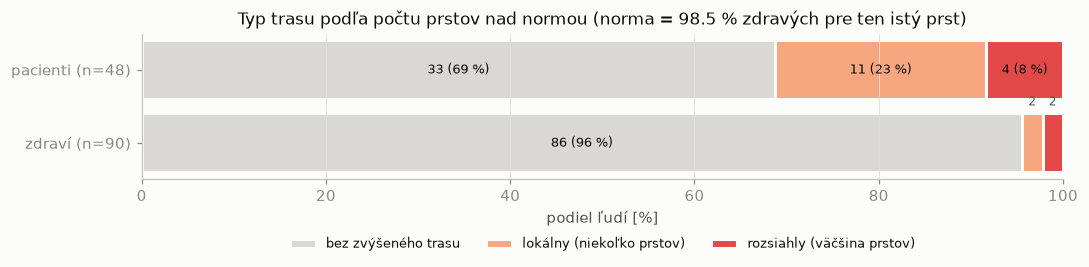

In [16]:
fig, ax = plt.subplots(figsize=(10, 2.8))
cols_t = {"bez zvýšeného trasu": "#d9d8d4", "lokálny (niekoľko prstov)": "#f6a77f", "rozsiahly (väčšina prstov)": "#e34948"}
names = {"pacient": f"pacienti (n={N_PAT})", "zdravý": f"zdraví (n={N_HEALTHY})"}
shares = pt_tab.div(pt_tab.sum(axis=1), axis=0) * 100
left = np.zeros(2)
for t in ORDER_T:
    ax.barh([names[i] for i in shares.index], shares[t], left=left, color=cols_t[t], edgecolor=SURFACE, lw=2, label=t)
    for i, (s, n) in enumerate(zip(shares[t], pt_tab[t])):
        if s >= 5:
            ax.text(left[i] + s / 2, i, f"{n} ({s:.0f} %)", ha="center", va="center", fontsize=8.5, color=INK)
        elif n > 0:
            ax.text(left[i] + s / 2, i - 0.47, str(n), ha="center", va="bottom", fontsize=8, color=INK2)
    left += shares[t].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("podiel ľudí [%]")
ax.set_title(f"Typ trasu podľa počtu prstov nad normou (norma = {100 * Q:.1f} % zdravých pre ten istý prst)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32), fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "23_typ_trasu.png", dpi=150); plt.show()

**Pacienti so zvýšeným trasom po prstoch.** Riadok = pacient, stĺpec = prst. Farba = koľkokrát je tras prsta
väčší ako typický zdravý **pre ten istý prst** (biela ≈ 1). Bodka = prst nad normou. Šedá = prst netlačil.
Pacienti bez zvýšeného trasu nie sú zobrazení.

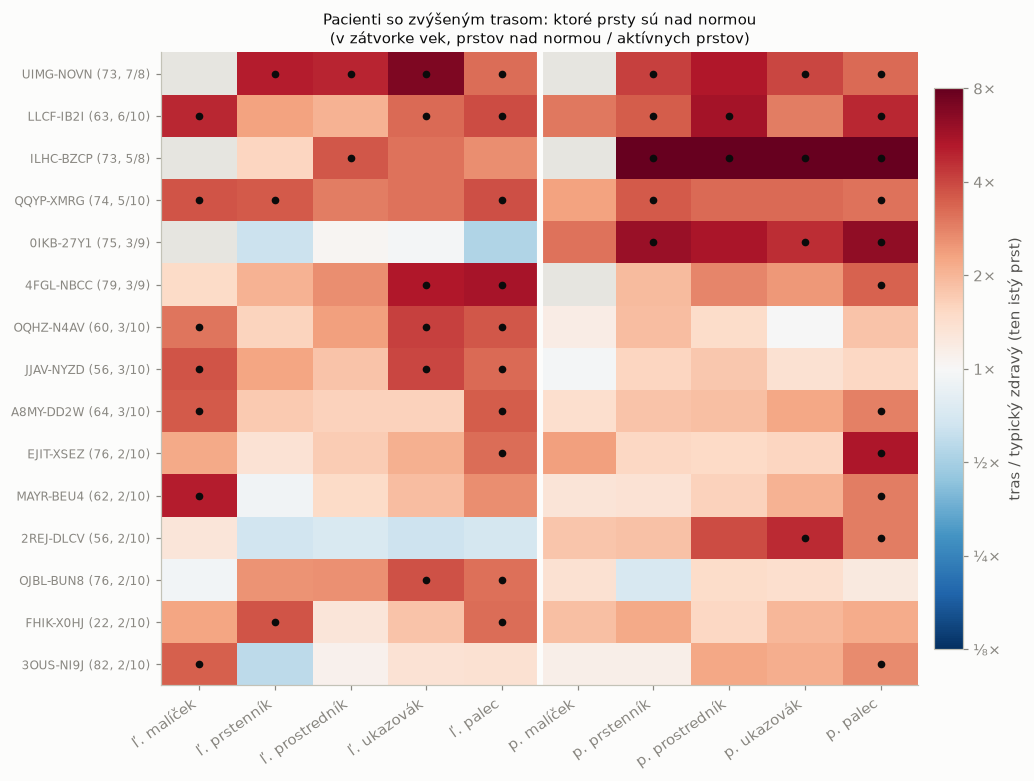

In [17]:
sel = PATTERN[(PATTERN.skupina == "pacient") & (PATTERN.typ_trasu != ORDER_T[0])]
sel = sel.assign(mx=NORM.loc[sel.index].max(axis=1)).sort_values(["prstov_nad_normou", "mx"], ascending=False)
M = np.log2(NORM.loc[sel.index, rf.FINGER_NAMES].to_numpy(dtype=float))
fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(sel) + 1.8))
cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("#e6e5e0")
im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=-3, vmax=3, aspect="auto")
yy, xx = np.nonzero(ABOVE.loc[sel.index, rf.FINGER_NAMES].to_numpy())
ax.scatter(xx, yy, s=16, color=INK)
ax.set_xticks(range(10), LABELS, rotation=35, ha="right")
ax.set_yticks(range(len(sel)), [f"{pid} ({r.vek}, {r.prstov_nad_normou}/{r.aktivnych_prstov})" for pid, r in sel.iterrows()],
              fontsize=8)
ax.axvline(4.5, color=SURFACE, lw=4); ax.grid(False)
cb = fig.colorbar(im, ax=ax, ticks=[-3, -2, -1, 0, 1, 2, 3], fraction=0.035, pad=0.02)
cb.ax.set_yticklabels(["⅛×", "¼×", "½×", "1×", "2×", "4×", "8×"]); cb.set_label("tras / typický zdravý (ten istý prst)")
ax.set_title("Pacienti so zvýšeným trasom: ktoré prsty sú nad normou\n(v zátvorke vek, prstov nad normou / aktívnych prstov)",
             fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "24_prsty_pacientov.png", dpi=150); plt.show()

In [18]:
# Na ktorej ruke je tras a je to slabšia ruka?
pat_t = PATTERN[(PATTERN.skupina == "pacient") & (PATTERN.typ_trasu != ORDER_T[0])].join(
    WEAK.set_index("patient_id")[["sila_lava", "sila_prava", "aspon_raz"]])
pat_t["slabsia_ruka"] = np.where(pat_t.sila_lava < pat_t.sila_prava, "ľavá", "pravá")
print("Pacienti so zvýšeným trasom – ruka s viac prstami nad normou vs. slabšia ruka:")
display(pd.crosstab(pat_t.ruka_s_trasom, pat_t.slabsia_ruka, margins=True, margins_name="spolu"))
print("Z nich s málo používanou rukou (aspoň v 1 vyšetrení):", ", ".join(pat_t.index[pat_t.aspon_raz]) or "nikto")
# Je tras viac na jednej ruke? Medián prstov ruky (voči norme prsta), pomer vyššej a nižšej ruky
hand_med = pd.DataFrame({"ľavá": NORM[rf.FINGER_NAMES[:5]].median(axis=1), "pravá": NORM[rf.FINGER_NAMES[5:]].median(axis=1)})
ASYM = hand_med.max(axis=1) / hand_med.min(axis=1)
asym_t = ASYM.loc[pat_t.index]
asym_h = ASYM.loc[PEOPLE.patient_id[H]]
print(f"Tras ruky (medián prstov voči norme), pomer horšej a lepšej ruky: pacienti so zvýšeným trasom medián "
      f"{asym_t.median():.2f}, zdraví medián {asym_h.median():.2f}; aspoň 1,5× u {(asym_t >= 1.5).sum()} z {len(asym_t)} "
      f"pacientov a u {(asym_h >= 1.5).mean() * 100:.0f} % zdravých")
h_alarm = PATTERN[(PATTERN.skupina == "zdravý") & (PATTERN.typ_trasu != ORDER_T[0])]
print("Zdraví s ≥ 2 prstami nad normou:")
display(h_alarm[["podskupina", "vek", "prstov_nad_normou", "aktivnych_prstov", "typ_trasu"]])

Pacienti so zvýšeným trasom – ruka s viac prstami nad normou vs. slabšia ruka:


slabsia_ruka,pravá,ľavá,spolu
ruka_s_trasom,,,
obe rovnako,2,2,4
pravá,1,2,3
ľavá,5,3,8
spolu,8,7,15


Z nich s málo používanou rukou (aspoň v 1 vyšetrení): 0IKB-27Y1, 3OUS-NI9J, EJIT-XSEZ, ILHC-BZCP, OQHZ-N4AV
Tras ruky (medián prstov voči norme), pomer horšej a lepšej ruky: pacienti so zvýšeným trasom medián 1.34, zdraví medián 1.25; aspoň 1,5× u 7 z 15 pacientov a u 10 % zdravých
Zdraví s ≥ 2 prstami nad normou:


,podskupina,vek,prstov_nad_normou,aktivnych_prstov,typ_trasu
patient_id,,,,,
1902202505,zdraví TUKE 2025-02,20,4,8,rozsiahly (väčšina prstov)
2102202511,zdraví TUKE 2025-02,66,2,10,lokálny (niekoľko prstov)
2102202516,zdraví TUKE 2025-02,56,2,10,lokálny (niekoľko prstov)
992606,zdraví 9_9_2026 (starší),85,8,9,rozsiahly (väčšina prstov)


In [19]:
n_up = int((pt_tab.loc["pacient", ORDER_T[1:]]).sum())
display(Markdown(f'''
**Záver 3.3:**
- Pri norme „vyšší tras ako {100 * Q:.1f} % zdravých pre ten istý prst“ má **{pct(n_up, N_PAT)} pacientov**
  zvýšený tras aspoň na 2 prstoch, oproti {pct(int(pt_tab.loc["zdravý", ORDER_T[1:]].sum()), N_HEALTHY)} zdravých.
- U väčšiny z nich **nie je tras rovnaký na všetkých prstoch**: {pt_tab.loc["pacient", ORDER_T[1]]} má **lokálny** tras
  (niekoľko prstov, ostatné v norme) a {pt_tab.loc["pacient", ORDER_T[2]]} **rozsiahly** (väčšina prstov).
- **Pozor na výklad „lokálny“:** mapa ukazuje, že u mnohých pacientov je tras zvýšený (červená) na väčšine prstov
  aspoň jednej ruky, len prísnu normu prekročia najsilnejšie prsty. Delenie lokálny / rozsiahly preto závisí od
  prísnosti normy (tabuľka prahov) – s miernejšou normou (97,5 %) by zvýšený tras malo viac pacientov, ale aj
  viac zdravých (~8 %).
- **Rozdiel medzi rukami:** u {(asym_t >= 1.5).sum()} z {len(asym_t)} pacientov so zvýšeným trasom má jedna ruka tras
  aspoň 1,5× väčší ako druhá (u zdravých len {(asym_h >= 1.5).mean() * 100:.0f} %) – u časti pacientov je tras
  **jednostranný**. Ruka s trasom pritom **nie je systematicky slabšia ruka** (tabuľka vyššie).
- Medzi zdravými so zvýšeným trasom je 85-ročná 992606 s trasom na 8 z 9 prstov (rovnako u kolegu). Keďže sa
  meria len v ustálených úsekoch, môže ísť o skutočný (napr. starecký) tras, nie o chybu merania.
'''))


**Záver 3.3:**
- Pri norme „vyšší tras ako 98.5 % zdravých pre ten istý prst“ má **15 z 48 (31 %) pacientov**
  zvýšený tras aspoň na 2 prstoch, oproti 4 z 90 (4 %) zdravých.
- U väčšiny z nich **nie je tras rovnaký na všetkých prstoch**: 11 má **lokálny** tras
  (niekoľko prstov, ostatné v norme) a 4 **rozsiahly** (väčšina prstov).
- **Pozor na výklad „lokálny“:** mapa ukazuje, že u mnohých pacientov je tras zvýšený (červená) na väčšine prstov
  aspoň jednej ruky, len prísnu normu prekročia najsilnejšie prsty. Delenie lokálny / rozsiahly preto závisí od
  prísnosti normy (tabuľka prahov) – s miernejšou normou (97,5 %) by zvýšený tras malo viac pacientov, ale aj
  viac zdravých (~8 %).
- **Rozdiel medzi rukami:** u 7 z 15 pacientov so zvýšeným trasom má jedna ruka tras
  aspoň 1,5× väčší ako druhá (u zdravých len 10 %) – u časti pacientov je tras
  **jednostranný**. Ruka s trasom pritom **nie je systematicky slabšia ruka** (tabuľka vyššie).
- Medzi zdravými so zvýšeným trasom je 85-ročná 992606 s trasom na 8 z 9 prstov (rovnako u kolegu). Keďže sa
  meria len v ustálených úsekoch, môže ísť o skutočný (napr. starecký) tras, nie o chybu merania.


## 4. Porovnanie s analýzou kolegu (repozitár `Rehapiano not mine`)

Kolega riešil tú istú úlohu inou metódou. Hlavné rozdiely v metóde:

| | kolega | táto analýza |
|---|---|---|
| tras | celý úsek 3–15 s, pásmo 4–15 Hz | len ustálené úseky, pásmo 3,5–15 Hz (prudké stlačenia vynechané) |
| sila prsta | norma pre ten istý prst, bez úpravy na silu | úprava na silu **a** norma pre ten istý prst |
| norma | zdraví ≥ 50 rokov (24 ľudí) | všetci zdraví (90), kontrola so zdravými ≥ 50 |
| slabá ruka | len pomer rúk, z priemeru vyšetrení | sila aj pomer, každé vyšetrenie zvlášť |
| falošné poplachy | prah z ≈ 2,5 % na prst, podiel u zdravých neoverený | prah nastavený na ≤ 5 % zdravých (leave-one-out) |

In [20]:
from pathlib import Path
COL = Path("Rehapiano not mine") / "outputs" / "stats"
if COL.exists():
    k_weak = pd.read_csv(COL / "weak_hand_patients.csv")
    k_pat = pd.read_csv(COL / "tremor_pattern.csv")
    k_cnt = pd.crosstab(k_pat.group, k_pat.pattern)
    ours_p = pt_tab.loc["pacient"]; ours_h = pt_tab.loc["zdravý"]
    comp = pd.DataFrame({
        "kolega": [int((k_weak.group == "patient").sum()), int(k_cnt.loc["patient"].drop("none", errors="ignore").sum()),
                   int(k_cnt.loc["control"].drop("none", errors="ignore").sum())],
        "táto analýza": [f"{int(tab.loc['pacient'].iloc[0])} (aspoň raz) / {int(tab.loc['pacient'].iloc[1])} (väčšina) / "
                         f"{int(tab.loc['pacient'].iloc[2])} (z priemeru)", int(ours_p[ORDER_T[1:]].sum()),
                         int(ours_h[ORDER_T[1:]].sum())]},
        index=["pacienti so slabo používanou rukou", "pacienti s trasom na ≥ 2 prstoch", "zdraví s trasom na ≥ 2 prstoch"])
    display(comp)
    print("Kolegovi zdraví s ‚trasom‘:", ", ".join(f"{r.patient_id} ({r.age} r., {r.pattern})"
                                                   for _, r in k_pat[(k_pat.group == "control") & (k_pat.pattern != "none")].iterrows()))
else:
    print("Priečinok s výsledkami kolegu sa nenašiel.")

,kolega,táto analýza
pacienti so slabo používanou rukou,6,9 (aspoň raz) / 5 (väčšina) / 6 (z priemeru)
pacienti s trasom na ≥ 2 prstoch,19,15
zdraví s trasom na ≥ 2 prstoch,5,4


Kolegovi zdraví s ‚trasom‘: 992606 (85 r., generalized), 1302202503 (22 r., localized), 1902202505 (20 r., localized), 1902202511 (18 r., localized), 2102202511 (66 r., localized)


- **Slabá ruka:** keď počítame rovnako ako kolega (z priemeru vyšetrení), dostaneme rovnakých 6 pacientov.
  Navyše ukazujeme 3 pacientov, ktorí mali slabú ruku len v jednom z dvoch vyšetrení.
- **Tras prstov:** počty sú podobné (kolega 19 pacientov a 5 zdravých, my 15 a 4); kolega má miernejší prah
  (≈ 97,5 % na prst), preto viac pacientov. Oba prístupy sa zhodujú v hlavných záveroch: pacienti majú vyšší tras
  na všetkých prstoch a zvýšený tras nie je na všetkých prstoch rovnaký.
- Táto analýza navyše ukazuje, ktoré prsty sú spoľahlivo merateľné (šum snímača), že prsty sa líšia už u zdravých
  aj po úprave na silu, ktoré prsty sú u pacientov zasiahnuté najviac (palce, ukazováky) a že tras je často
  jednostranný.

In [21]:
out = PF[["patient_id", "skupina", "podskupina", "vek", "prst", "nazov", "sila", "tras_SD", "tras_relativny", "iteracii"]].copy()
out["tras_voci_norme_prsta"] = [NORM.at[p, c] for p, c in zip(out.patient_id, out.prst)]
out["nad_normou"] = [bool(ABOVE.at[p, c]) for p, c in zip(out.patient_id, out.prst)]
out.to_csv("tras_prstov.csv", sep=";", index=False, float_format="%.6g", encoding="utf-8-sig")
people_out = (PEOPLE.set_index("patient_id")
              .join(WEAK.set_index("patient_id")[["vysetreni", "slabych_vysetreni", "slabsia_ruka", "pomer_min",
                                                  "pomer_z_priemeru", "aspon_raz", "vo_vacsine", "z_priemeru"]])
              .join(PATTERN[["prstov_nad_normou", "aktivnych_prstov", "typ_trasu", "ruka_s_trasom"]]))
people_out.reset_index().to_csv("uloha3_ludia.csv", sep=";", index=False, float_format="%.6g", encoding="utf-8-sig")
print(f"tras_prstov.csv: {len(out)} riadkov (človek × prst); uloha3_ludia.csv: {len(people_out)} riadkov (človek)")

tras_prstov.csv: 1313 riadkov (človek × prst); uloha3_ludia.csv: 138 riadkov (človek)


In [22]:
display(Markdown(f'''
## 5. Zhrnutie

1. **Vek:** pacienti (medián {PEOPLE.vek[PAT].median():.1f} r.) sú výrazne starší ako zdraví (medián
   {PEOPLE.vek[H].median():.0f} r.); vekom porovnateľných je len 24 zdravých ≥ 50 rokov. Histogram: obr. 18.
2. **Slabo používaná ruka:** úplne nepoužívanú ruku nemá nikto. Málo používanú ruku má aspoň v jednom vyšetrení
   **{pct(int(tab.loc["pacient"].iloc[0]), N_PAT)} pacientov**, stabilne (vo väčšine vyšetrení)
   **{int(tab.loc["pacient"].iloc[1])}**; u zdravých {int(tab.loc["zdravý"].iloc[0])} z {N_HEALTHY}. Obr. 19.
3. **Tras prstov:**
   - tras je merateľný na všetkých prstoch, ale prstenníky sú len ~2× nad šumom snímača (obr. 20),
   - prsty sa líšia **už u zdravých** (malíčky sa trasú relatívne najviac, prstenníky najmenej) – preto sa každý
     prst porovnáva s normou toho istého prsta (obr. 21),
   - pacienti majú vyšší tras **na všetkých prstoch**, najviac na **palcoch a ukazovákoch** (~2×) (obr. 22),
   - u {pct(n_up, N_PAT)} pacientov je tras zvýšený na ≥ 2 prstoch (zdraví {int(pt_tab.loc["zdravý", ORDER_T[1:]].sum())}
     z {N_HEALTHY}); prísnu normu prekročí väčšinou len niekoľko prstov (lokálny tras), u {(asym_t >= 1.5).sum()} z
     {len(asym_t)} je jedna ruka aspoň 1,5× horšia ako druhá (zdraví {(asym_h >= 1.5).mean() * 100:.0f} %) (obr. 23, 24).

**Obmedzenia:** zdraví a pacienti hrali hru s rôznym nastavením (rôzny `step_id`); poradie prstov na snímačoch
je odvodené zo síl, nie overené; zdravých ≥ 50 rokov je len 24; počty „prstov nad normou“ závisia od zvoleného
prahu (tabuľka v 3.3).

**Možné pokračovanie:** koherencia trasu medzi prstami jednej ruky – ak prsty kmitajú synchrónne na rovnakej
frekvencii, tras má spoločný (centrálny) zdroj; ak nie, ide o lokálny tras alebo šum.
'''))


## 5. Zhrnutie

1. **Vek:** pacienti (medián 66.5 r.) sú výrazne starší ako zdraví (medián
   24 r.); vekom porovnateľných je len 24 zdravých ≥ 50 rokov. Histogram: obr. 18.
2. **Slabo používaná ruka:** úplne nepoužívanú ruku nemá nikto. Málo používanú ruku má aspoň v jednom vyšetrení
   **9 z 48 (19 %) pacientov**, stabilne (vo väčšine vyšetrení)
   **5**; u zdravých 3 z 90. Obr. 19.
3. **Tras prstov:**
   - tras je merateľný na všetkých prstoch, ale prstenníky sú len ~2× nad šumom snímača (obr. 20),
   - prsty sa líšia **už u zdravých** (malíčky sa trasú relatívne najviac, prstenníky najmenej) – preto sa každý
     prst porovnáva s normou toho istého prsta (obr. 21),
   - pacienti majú vyšší tras **na všetkých prstoch**, najviac na **palcoch a ukazovákoch** (~2×) (obr. 22),
   - u 15 z 48 (31 %) pacientov je tras zvýšený na ≥ 2 prstoch (zdraví 4
     z 90); prísnu normu prekročí väčšinou len niekoľko prstov (lokálny tras), u 7 z
     15 je jedna ruka aspoň 1,5× horšia ako druhá (zdraví 10 %) (obr. 23, 24).

**Obmedzenia:** zdraví a pacienti hrali hru s rôznym nastavením (rôzny `step_id`); poradie prstov na snímačoch
je odvodené zo síl, nie overené; zdravých ≥ 50 rokov je len 24; počty „prstov nad normou“ závisia od zvoleného
prahu (tabuľka v 3.3).

**Možné pokračovanie:** koherencia trasu medzi prstami jednej ruky – ak prsty kmitajú synchrónne na rovnakej
frekvencii, tras má spoločný (centrálny) zdroj; ak nie, ide o lokálny tras alebo šum.
